# Gradient boosting: correct the current model

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/tree-based/08-gradient-boosting.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

Gradient boosting builds an ensemble sequentially, just as AdaBoost does. But
its mechanism is different. To make the idea direct, we use a **regression**
problem: predict continuous NOx concentration from gas-turbine operating
measurements.

The model starts with one constant prediction. Each new shallow **regression
tree** then learns a continuous correction to the current prediction.

## What you will do

1. Build a high-level mental model of boosting as sequential error correction.
2. Contrast gradient boosting with bagging and AdaBoost.
3. Set up one NOx regression task with a fixed train/test split.
4. Connect residual correction to the word *gradient* (optional).
5. Fit small regression trees that supply continuous corrections.
6. Add the corrections gradually, then evaluate the growing model on the same
   held-out observations.


## The high-level idea: repair a running forecast

Gradient boosting builds one prediction through a sequence of small
revisions. It does **not** ask every tree to predict NOx from scratch.
Instead, each new tree asks: **where is the current model still
systematically too high or too low?**

During training, we repeat this repair loop:

1. Start from the current prediction for every training observation.
2. Compare it with the measured NOx and calculate the remaining error.
3. Fit a small regression tree to recognize operating regions with similar
   remaining errors.
4. Add only part of that tree's correction to the current prediction.
5. Repeat, so the next tree focuses only on what remains unexplained.

Thus, the final model is an **additive model**:

$$
\hat{y}^{(T)}(\mathbf{x})
= \overline{y}_{\mathrm{train}}
+ \eta g_1(\mathbf{x})
+ \eta g_2(\mathbf{x})
+ \cdots
+ \eta g_T(\mathbf{x}).
$$

Here, $\overline{y}_{\mathrm{train}}$ is the initial mean-NOx forecast,
each $g_t(\mathbf{x})$ is the continuous correction supplied by a shallow
regression tree, and $\eta$ retains only a fraction of each correction.

> **Key idea:** a tree in gradient boosting predicts a **correction**, not a
> complete NOx value. Many small corrections, added together, form a flexible
> nonlinear model.

At prediction time, measured NOx is unknown. A new observation simply passes
through the already-fitted trees, and the model adds their learned
feature-dependent corrections to the baseline.


### A tiny staged example

For one *training* observation, imagine that the current forecast is
$65.0\ \mathrm{mg/m^3}$ while the measured NOx is
$78.0\ \mathrm{mg/m^3}$. The numbers below are illustrative; a real tree
learns its correction from many observations with similar operating
conditions.

| Stage | Current forecast | Remaining residual | Next tree's correction | Applied update, $\eta=0.1$ |
| --- | ---: | ---: | ---: | ---: |
| Baseline | 65.0 | $78.0 - 65.0 = +13.0$ | $+9.0$ | $+0.9$ |
| After tree 1 | 65.9 | $78.0 - 65.9 = +12.1$ | $+7.0$ | $+0.7$ |
| After tree 2 | 66.6 | $78.0 - 66.6 = +11.4$ | $\cdots$ | $\cdots$ |

The next tree does not redo the entire prediction. It targets the remaining
residual after the earlier corrections have already been applied.


### How this differs from the earlier ensembles

| Method | How trees are trained | What later trees respond to | How predictions combine | Main intuition |
| --- | --- | --- | --- | --- |
| Bagging / random forest | Independently | No earlier-tree result | Average tree predictions | Reduce the variance of an unstable tree |
| AdaBoost | Sequentially, with changing sample weights | Samples earlier stumps misclassify | Weighted vote | Put more attention on hard classification cases |
| Gradient boosting | Sequentially | The current numerical residual | Sum of shrunken corrections | Reduce the remaining prediction error stage by stage |

So gradient boosting is sequential like AdaBoost, but it is **not** bootstrap
aggregation and it is **not** sample reweighting. Its next tree is trained on
what the current model still gets wrong.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

sns.set_theme(style="whitegrid", context="notebook")

## 1. Set up one regression task

We predict measured NOx concentration using three familiar gas-turbine
measurements: ambient temperature (AT), compressor discharge pressure (CDP),
and turbine energy yield (TEY). We keep one fixed 70/30 train/test split
throughout this notebook. The test observations are never used to fit a
correction tree.

In [2]:
FEATURES = ["AT", "CDP", "TEY"]
TARGET = "NOX"
RANDOM_STATE = 4520

data_candidates = [
    Path("../data/gas-turbine-course.csv"),
    Path("site/data/gas-turbine-course.csv"),
    Path("gas-turbine-course.csv"),
]
data_path = next(
    (path for path in data_candidates if path.exists()),
    data_candidates[-1],
)
data = pd.read_csv(filepath_or_buffer=data_path)
model_data = data[FEATURES + [TARGET]].dropna().copy()

X_train, X_test, y_train, y_test = train_test_split(
    model_data[FEATURES],
    model_data[TARGET],
    test_size=0.30,
    random_state=RANDOM_STATE,
)

print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")
print(f"Training mean NOx: {y_train.mean():.2f} mg/m³")

Training observations: 25,713
Test observations: 11,020
Training mean NOx: 65.28 mg/m³


## 2. Start from one simple forecast

Before fitting any tree, let us predict the same value for every training
observation: the average training NOx. It is intentionally crude, but it
gives the first correction tree a clear place to start.

For training observation $i$, the remaining error is its **residual**:

$$
r_i = y_i - \hat{y}_i.
$$

A positive residual means that the current forecast is too low; a negative
residual means it is too high. The table below shows two actual training
observations. A correction tree will receive every observation's operating
features together with a residual like this one, then look for regions that
need similar signed corrections.


In [3]:
def residuals(*, targets: np.ndarray, predictions: np.ndarray) -> np.ndarray:
    """Compute observed-minus-predicted residuals.

    Args:
        targets: Measured target values.
        predictions: Current model predictions.

    Returns:
        One residual per observation.
    """
    return targets - predictions


train_targets = y_train.to_numpy(dtype=float)
test_targets = y_test.to_numpy(dtype=float)
baseline_prediction = float(train_targets.mean())
baseline_train_predictions = np.full(
    shape=len(X_train),
    fill_value=baseline_prediction,
    dtype=float,
)
baseline_test_predictions = np.full(
    shape=len(X_test),
    fill_value=baseline_prediction,
    dtype=float,
)
baseline_residuals = residuals(
    targets=train_targets,
    predictions=baseline_train_predictions,
)

# Select one representative positive and negative residual for display.
representative_residuals = (12.5, -10.0)
example_train_positions = [
    int(np.argmin(np.abs(baseline_residuals - representative_residual)))
    for representative_residual in representative_residuals
]

residual_examples = pd.DataFrame(
    {
        "Example": ["Forecast too low", "Forecast too high"],
        "AT (°C)": X_train.iloc[example_train_positions]["AT"].to_numpy(),
        "CDP": X_train.iloc[example_train_positions]["CDP"].to_numpy(),
        "TEY": X_train.iloc[example_train_positions]["TEY"].to_numpy(),
        "Measured NOx (mg/m³)": train_targets[example_train_positions],
        "Forecast (mg/m³)": baseline_train_predictions[example_train_positions],
        "Residual (mg/m³)": baseline_residuals[example_train_positions],
    }
)

print(f"Initial forecast for every training row: {baseline_prediction:.2f} mg/m³")
residual_examples.style.hide(axis="index").format(
    {
        "AT (°C)": "{:.2f}",
        "CDP": "{:.2f}",
        "TEY": "{:.2f}",
        "Measured NOx (mg/m³)": "{:.2f}",
        "Forecast (mg/m³)": "{:.2f}",
        "Residual (mg/m³)": "{:+.2f}",
    }
)

Initial forecast for every training row: 65.28 mg/m³


Example,AT (°C),CDP,TEY,Measured NOx (mg/m³),Forecast (mg/m³),Residual (mg/m³)
Forecast too low,8.97,14.05,163.29,77.78,65.28,+12.50
Forecast too high,29.59,13.08,145.17,55.28,65.28,-10.00


## 3. Fit the first correction tree

The first tree is not asked to predict NOx itself. Its training target is the
current residual, so its leaf values say how much the baseline prediction
should move within each region.

At a boosting stage, the base learner is a **regression tree**. Its output is
a continuous correction, in NOx units, rather than a class label or a
probability. Here, the tree is trained to approximate the current residuals.

A depth-1 tree stump would be valid, just as it was for AdaBoost. We use a
depth-2 tree here so one
correction can distinguish up to four simple operating regions; the depth is
a hyperparameter, not a rule. Each terminal-region value shown below is the
unshrunk tree output $g_t(\mathbf{x})$. The learning rate is applied to that
output in the next step.

For this first stage, we fit a **DecisionTreeRegressor** directly. Later, we
will use **GradientBoostingRegressor** to automate the repeated correction
process.


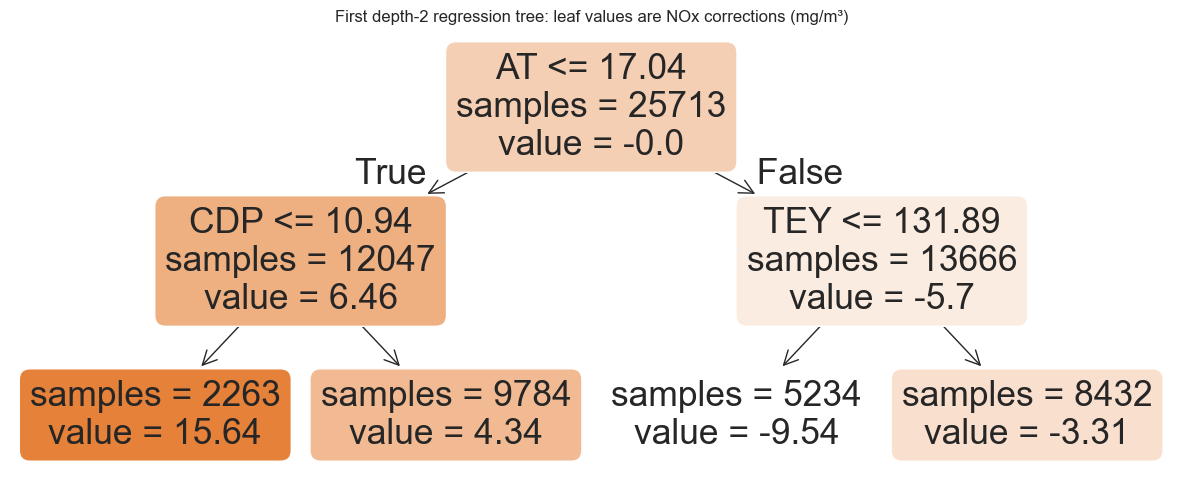

In [4]:
LEARNING_RATE = 0.10
MAX_DEPTH = 2
MIN_SAMPLES_LEAF = 50

first_correction_tree = DecisionTreeRegressor(
    max_depth=MAX_DEPTH,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    random_state=RANDOM_STATE,
)
first_correction_tree.fit(X=X_train, y=baseline_residuals)

fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(
    decision_tree=first_correction_tree,
    feature_names=FEATURES,
    filled=True,
    rounded=True,
    impurity=False,
    precision=2,
    ax=ax,
)
ax.set_title("First depth-2 regression tree: leaf values are NOx corrections (mg/m³)")
plt.show()

## 4. Add the tree's correction to the current prediction

Let $g_t(\mathbf{x})$ be the correction supplied by tree $t$. The update is

$$
\hat{y}_t(\mathbf{x})
= \hat{y}_{t-1}(\mathbf{x})
+ \eta g_t(\mathbf{x}),
$$

where $\eta$ is the learning rate. It shrinks each correction so one tree does
not change the model too aggressively. Here, $\eta = 0.10$.

For a genuinely new observation, its measured NOx value is unknown. The
tree selects $g_t(\mathbf{x})$ using only its features. In the worked
held-out example below, we reveal the measured NOx **afterward** so that we
can compare the evolving prediction with the ground truth.

In [5]:
first_tree_correction = first_correction_tree.predict(X=X_train)
manual_first_predictions = (
    baseline_train_predictions + LEARNING_RATE * first_tree_correction
)

print(
    "Training MSE before / after the first correction: "
    f"{mean_squared_error(y_true=train_targets, y_pred=baseline_train_predictions):.2f}"
    " / "
    f"{mean_squared_error(y_true=train_targets, y_pred=manual_first_predictions):.2f}"
)

EXAMPLE_TEST_POSITION = 133
example_features = X_test.iloc[[EXAMPLE_TEST_POSITION]]
example_target = float(test_targets[EXAMPLE_TEST_POSITION])
example_prediction_before = float(baseline_test_predictions[EXAMPLE_TEST_POSITION])
example_residual_before = example_target - example_prediction_before
example_tree_correction = float(
    first_correction_tree.predict(X=example_features)[0]
)
example_prediction_after = (
    example_prediction_before + LEARNING_RATE * example_tree_correction
)

example_update = pd.DataFrame(
    {
        "Observed NOx (post-hoc, mg/m³)": [example_target],
        "Prediction before (mg/m³)": [example_prediction_before],
        "Post-hoc error before (mg/m³)": [example_residual_before],
        "Tree correction g₁(x) (mg/m³)": [example_tree_correction],
        "Prediction after (mg/m³)": [example_prediction_after],
    }
)
example_update.style.format(
    {
        "Observed NOx (post-hoc, mg/m³)": "{:.2f}",
        "Prediction before (mg/m³)": "{:.2f}",
        "Post-hoc error before (mg/m³)": "{:+.2f}",
        "Tree correction g₁(x) (mg/m³)": "{:+.2f}",
        "Prediction after (mg/m³)": "{:.2f}",
    }
)

Training MSE before / after the first correction: 135.56 / 125.90


,"Observed NOx (post-hoc, mg/m³)",Prediction before (mg/m³),Post-hoc error before (mg/m³),Tree correction g₁(x) (mg/m³),Prediction after (mg/m³)
0,77.91,65.28,+12.63,+4.34,65.71


## 5. Repeat the correction process

We have now carried out one boosting step by hand: fit a tree to the current
residuals, shrink its correction, and add it to the forecast. Next,
**GradientBoostingRegressor** automates 60 repetitions of that same loop.
At every stage, the next tree sees the residuals left by all earlier trees and
adds another shrunk correction. We evaluate every intermediate model on the
same test data.

In [6]:
def staged_metrics(
    *,
    model: GradientBoostingRegressor,
    training_features: pd.DataFrame,
    training_targets: pd.Series,
    test_features: pd.DataFrame,
    test_targets: pd.Series,
) -> pd.DataFrame:
    """Measure regression performance after each boosting stage.

    Args:
        model: A fitted gradient-boosting regressor.
        training_features: Feature table used to fit the model.
        training_targets: Continuous training targets.
        test_features: Held-out feature table.
        test_targets: Continuous held-out targets.

    Returns:
        One row per boosting stage with training/test MSE and test R-squared.
    """
    rows = []
    staged_training_predictions = model.staged_predict(X=training_features)
    staged_test_predictions = model.staged_predict(X=test_features)
    for stage, (training_prediction, test_prediction) in enumerate(
        zip(
            staged_training_predictions,
            staged_test_predictions,
            strict=True,
        ),
        start=1,
    ):
        rows.append(
            {
                "Stage": stage,
                "Training MSE": mean_squared_error(
                    y_true=training_targets,
                    y_pred=training_prediction,
                ),
                "Test MSE": mean_squared_error(
                    y_true=test_targets,
                    y_pred=test_prediction,
                ),
                "Test R²": r2_score(
                    y_true=test_targets,
                    y_pred=test_prediction,
                ),
            }
        )
    return pd.DataFrame(rows)


boosted_model = GradientBoostingRegressor(
    loss="squared_error",
    n_estimators=60,
    learning_rate=LEARNING_RATE,
    max_depth=MAX_DEPTH,
    min_samples_leaf=MIN_SAMPLES_LEAF,
    random_state=RANDOM_STATE,
)
boosted_model.fit(X=X_train, y=y_train)

history = staged_metrics(
    model=boosted_model,
    training_features=X_train,
    training_targets=y_train,
    test_features=X_test,
    test_targets=y_test,
)
history.loc[
    history["Stage"].isin([1, 10, 20, 40, 60]),
].reset_index(drop=True)

,Stage,Training MSE,Test MSE,Test R²
0,1,125.902271,128.289323,0.072358
1,10,83.549990,84.500501,0.388989
2,20,68.484672,68.884370,0.501907
3,40,60.479339,61.029373,0.558705
4,60,56.917286,57.511010,0.584146


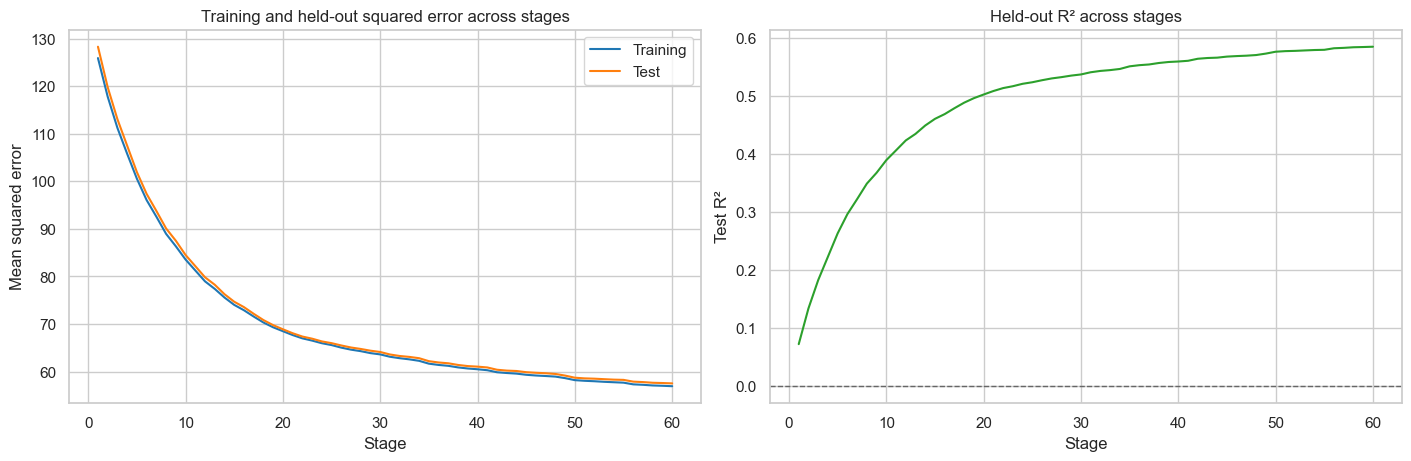

In [7]:
figure, axes = plt.subplots(
    ncols=2,
    figsize=(14, 4.5),
    constrained_layout=True,
)

sns.lineplot(
    data=history,
    x="Stage",
    y="Training MSE",
    ax=axes[0],
    label="Training",
    color="tab:blue",
)
sns.lineplot(
    data=history,
    x="Stage",
    y="Test MSE",
    ax=axes[0],
    label="Test",
    color="tab:orange",
)
axes[0].set_title("Training and held-out squared error across stages")
axes[0].set_ylabel("Mean squared error")

sns.lineplot(
    data=history,
    x="Stage",
    y="Test R²",
    ax=axes[1],
    color="tab:green",
)
axes[1].axhline(y=0, color="0.4", linestyle="--", linewidth=1)
axes[1].set_title("Held-out R² across stages")
axes[1].set_ylabel("Test R²")

plt.show()

## 6. The main knobs and takeaways

- **Learning rate $\eta$** controls the size of each correction. A smaller
  value usually requires more trees.
- **Number of trees** controls how long the sequential process runs. We use
  held-out performance to decide when additional corrections stop helping.
- **Tree depth and minimum leaf size** control the flexibility of each
  correction tree. Deeper trees can learn more complex corrections, but they
  also make overfitting easier.

A shallow tree can identify one broad, simple error pattern. The next tree is
then free to explain a different pattern left behind. Many small,
learning-rate-shrunk corrections can represent a complex response while we
monitor held-out performance and stop before overfitting.

AdaBoost and gradient boosting are both sequential ensembles, but their
training mechanisms differ:

- **AdaBoost:** reweights samples that earlier classifier stumps misclassify,
  then takes a weighted vote.
- **Gradient boosting:** fits regression trees to current residuals (more
  generally, negative loss gradients) and adds their continuous corrections.




## 7. (Optional) Why *gradient* boosting?

The residual-correction procedure above is already enough to use gradient
boosting. The word *gradient* explains why residuals are the right target for
squared-error regression—and how the same recipe extends to other losses.

Let $F_t(\mathbf{x})$ denote the **entire ensemble prediction function**
after $t$ trees, not one individual tree. Let $g_t(\mathbf{x})$ denote the
new regression tree added at stage $t$:

$$
F_t(\mathbf{x})
= F_{t-1}(\mathbf{x}) + \eta g_t(\mathbf{x}).
$$

Here, $\eta$ is the learning rate. The question is: what should the new
tree $g_t$ try to predict?

### 1. From parameter-space gradient descent to function-space gradient descent

For a linear model, ordinary gradient descent updates a fixed vector of
parameters:

$$
\boldsymbol{\theta}_t
= \boldsymbol{\theta}_{t-1}
- \eta\,\nabla_{\boldsymbol{\theta}}
\mathcal{L}(\boldsymbol{\theta}_{t-1}).
$$

Gradient boosting instead updates the prediction function $F$. On the
training data, that function can be represented by the vector of its current
predictions:

$$
\mathbf{f}
= \begin{bmatrix}
F(\mathbf{x}_1) \\
F(\mathbf{x}_2) \\
\vdots \\
F(\mathbf{x}_n)
\end{bmatrix}.
$$

Thus, instead of first asking how each parameter should change, we ask how
each current training prediction should change. A regression tree turns
those desired, observation-level changes into feature-based rules that can
also be applied to a new observation.

| Ordinary gradient descent | Gradient boosting |
| --- | --- |
| Update parameters $\boldsymbol{\theta}$ | Update the prediction function $F$ |
| Take $-\nabla_{\boldsymbol{\theta}}\mathcal{L}$ | Find a tree-shaped approximation to $-\nabla_F\mathcal{L}$ |
| Keep the same model form | Add one new regression tree |
| Final model is one parameterized equation | Final model is a sum of trees |

### 2. Squared-error regression: the negative gradient is the residual

For the mean squared-error objective, written in terms of the prediction
function,

$$
\mathcal{L}_{\mathrm{MSE}}(F)
= \frac{1}{n}\sum_{i=1}^{n}
\left[y_i - F(\mathbf{x}_i)\right]^2.
$$

The derivative is taken with respect to the function's value at a particular
training input, $F(\mathbf{x}_i)$:

$$
-\frac{\partial \mathcal{L}_{\mathrm{MSE}}(F)}
{\partial F(\mathbf{x}_i)}
= \frac{2}{n}\left[y_i - F(\mathbf{x}_i)\right].
$$

At stage $t$, define the current residual as

$$
r_i^{(t)}
= y_i - F_{t-1}(\mathbf{x}_i).
$$

Equivalently, the negative gradient over all $n$ current training
predictions is

$$
-\nabla_{\mathbf{f}}\mathcal{L}_{\mathrm{MSE}}(F)
= \frac{2}{n}
\begin{bmatrix}
r_1^{(t)} \\
r_2^{(t)} \\
\vdots \\
r_n^{(t)}
\end{bmatrix}.
$$

Therefore, the residual vector points in exactly the same direction as the
negative gradient; the positive constant $2/n$ only changes its scale and
can be absorbed into the learning rate. The next tree is fitted to these
residuals:

$$
g_t
= \operatorname*{arg\,min}_{g\in\mathcal{G}}
\sum_{i=1}^{n}
\left[r_i^{(t)} - g(\mathbf{x}_i)\right]^2,
$$

where $\mathcal{G}$ is the family of allowed regression trees. The tree is
an approximation to the unrestricted, observation-by-observation negative
gradient because it cannot prescribe an independent change for every
training observation. Instead, it identifies feature regions that need
similar corrections.

### 3. Binary classification: binary cross-entropy gives a different correction

For binary classification, gradient boosting still adds regression-tree
corrections. We maintain an unbounded **score** $F(\mathbf{x})$, then convert
it to a probability with the sigmoid function:

$$
p_i = \sigma\!\left(F(\mathbf{x}_i)\right)
= \frac{1}{1 + \exp\!\left[-F(\mathbf{x}_i)\right]}.
$$

Using binary cross-entropy,

$$
\mathcal{L}_{\mathrm{BCE}}(F)
= -\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right],
\qquad y_i\in\{0,1\},
$$

the negative gradient with respect to the **score** is

$$
-\frac{\partial \mathcal{L}_{\mathrm{BCE}}(F)}
{\partial F(\mathbf{x}_i)}
= \frac{1}{n}\left(y_i-p_i\right).
$$

Thus the next regression tree is fitted to the continuous
**pseudo-residual**

$$
q_i^{(t)}
= y_i - p_i^{(t-1)},
\qquad
p_i^{(t-1)}
= \sigma\!\left(F_{t-1}(\mathbf{x}_i)\right).
$$

The sign of $q_i^{(t)}$ is fixed by the label: it is positive when
$y_i=1$ and negative when $y_i=0$. Its **magnitude** is the useful
information. For a positive-label sample, $p_i^{(t-1)}\approx 0$ gives
$q_i^{(t)}\approx 1$ and calls for a large upward correction, whereas
$p_i^{(t-1)}\approx 1$ gives $q_i^{(t)}\approx 0$. Likewise, a
negative-label sample with $p_i^{(t-1)}\approx 1$ has
$q_i^{(t)}\approx -1$ and calls for a large downward correction; when
$p_i^{(t-1)}\approx 0$, its correction is near zero. The update remains

$$
F_t(\mathbf{x})
= F_{t-1}(\mathbf{x}) + \eta g_t(\mathbf{x}),
\qquad
p_t(\mathbf{x})
= \sigma\!\left(F_t(\mathbf{x})\right).
$$

The tree changes the raw score, not the probability directly. In practical
implementations, the tree's terminal values may receive an additional
loss-based optimization; the central first-order idea remains the same:
each new tree approximates the negative gradient of the current loss.

[Open the gradient-boosting explorer](08-gradient-boosting-explorer.qmd)  
[Return to Tree-based models](index.qmd)